# ЛР-2. Линейная и логистическая регрессия

Та же постановка: классификация направления по акциям, регрессия доходности по
облигациям. Линейные модели — точка отсчёта без нелинейностей: если дерево не
лучше линейной модели, то и смысла в нём нет.

Своя реализация: `src/linear.py` — градиентный спуск (логрегрессия, линейная
регрессия) и замкнутое решение ridge.


In [1]:
# --- общая подготовка: путь к корню репозитория, импорт своих модулей ---
import sys
from pathlib import Path

# корень репозитория ищем вверх по дереву по маркеру src/ — ноутбук можно
# запускать из своей папки или из корня
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.prep import StandardScaler, time_split
from src import metrics

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (7.5, 4)
plt.rcParams["axes.grid"] = True

In [2]:
# без файлов из data/processed дальше ничего не запустится — подсказываем, как их получить
for _name in ("shares_features.csv", "bonds_features.csv"):
    if not (ROOT / "data" / "processed" / _name).exists():
        raise FileNotFoundError(
            f"нет data/processed/{_name}: сначала выполни "
            "python scripts/fetch_moex.py и python scripts/build_features.py (см. README)"
        )

# --- данные: панели MOEX и хронологическое разбиение ---
shares = pd.read_csv(ROOT / "data/processed/shares_features.csv", parse_dates=["date"])
bonds = pd.read_csv(ROOT / "data/processed/bonds_features.csv", parse_dates=["date"])

SHARE_FEATS = [
    "ret_1", "ret_2", "ret_3", "ret_5", "ret_10", "ret_20",      # лаги доходности
    "vol_5", "vol_20",                                            # волатильность
    "ma_ratio_5", "ma_ratio_20",                                  # отклонение от средних
    "hl_range", "oc_range",                                       # диапазон дня
    "vol_rel", "val_rel", "trd_rel",                              # относительные объёмы
    "rsi_14", "weekday", "month", "market_ret_1",                 # RSI, календарь, рынок
]
BOND_FEATS = [
    "YIELDCLOSE", "dyield_1", "dyield_5", "dyield_20",            # уровень и изменения доходности
    "ret_1", "ret_5", "ret_20", "vol_20",                         # цена и волатильность
    "DURATION", "COUPONPERCENT", "years_to_mat",                  # параметры выпуска
    "val_rel", "trd_rel", "price_to_face", "is_ofz",              # ликвидность, ОФЗ
]

# обучение — прошлое, тест — будущее; перемешивать нельзя, иначе утечка из будущего
sh_tr, sh_te = time_split(shares, split_date="2025-01-01")
bd_tr, bd_te = time_split(bonds, split_date="2025-10-01")

Xc_tr, yc_tr = sh_tr[SHARE_FEATS].to_numpy("float32"), sh_tr["target_up"].to_numpy()
Xc_te, yc_te = sh_te[SHARE_FEATS].to_numpy("float32"), sh_te["target_up"].to_numpy()
Xr_tr, yr_tr = bd_tr[BOND_FEATS].to_numpy("float32"), bd_tr["target_next_yield"].to_numpy()
Xr_te, yr_te = bd_te[BOND_FEATS].to_numpy("float32"), bd_te["target_next_yield"].to_numpy()

# масштабирование обучаем только на трейне
sc_c, sc_r = StandardScaler().fit(Xc_tr), StandardScaler().fit(Xr_tr)
Xc_tr_s, Xc_te_s = sc_c.transform(Xc_tr), sc_c.transform(Xc_te)
Xr_tr_s, Xr_te_s = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)

print(f"акции:     {len(sh_tr):,} обучение / {len(sh_te):,} тест, признаков {len(SHARE_FEATS)}")
print(f"облигации: {len(bd_tr):,} обучение / {len(bd_te):,} тест, признаков {len(BOND_FEATS)}")
print("доля роста в тесте:", round(yc_te.mean(), 4))

акции:     37,154 обучение / 22,468 тест, признаков 19
облигации: 8,459 обучение / 10,468 тест, признаков 15
доля роста в тесте: 0.4633


In [3]:
# --- сохранение метрик для итогового сравнения (06_comparison.ipynb) ---
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
RESULT_FILE = RESULTS / "results.jsonl"


def save_result(lab, task, model, values):
    """Идемпотентно записывает строку метрик в results.jsonl."""
    rows = []
    if RESULT_FILE.exists():
        rows = [json.loads(line) for line in RESULT_FILE.read_text(encoding="utf-8").splitlines() if line]
    row = {"lab": lab, "task": task, "model": model,
           **{k: round(float(v), 4) for k, v in values.items()}}
    rows = [r for r in rows if not (r["lab"] == lab and r["task"] == task and r["model"] == model)]
    rows.append(row)
    RESULT_FILE.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in rows) + "\n",
                           encoding="utf-8")
    return row


def show(res):
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in res.items()})

## 1. Бейзлайн: sklearn

In [4]:
# --- бейзлайн sklearn: логистическая регрессия и ridge ---
from sklearn.linear_model import LogisticRegression, Ridge

base_c = LogisticRegression(max_iter=3000, C=1.0).fit(Xc_tr_s, yc_tr)
r = metrics.classification_report(yc_te, base_c.predict(Xc_te_s),
                                  base_c.predict_proba(Xc_te_s)[:, 1])
show(r); save_result("lab2_linear", "classification", "sklearn logreg", r)

base_r = Ridge(alpha=1.0).fit(Xr_tr_s, yr_tr)
rr = metrics.regression_report(yr_te, base_r.predict(Xr_te_s))
show(rr); save_result("lab2_linear", "regression", "sklearn ridge", rr)

# наивный прогноз «завтра = сегодня» — нижняя планка для регрессии
naive = metrics.regression_report(yr_te, bd_te["YIELDCLOSE"].to_numpy())
show(naive); save_result("lab2_linear", "regression", "naive (yield_t)", naive)

{'accuracy': 0.5111, 'precision': 0.4638, 'recall': 0.3534, 'f1': 0.4012, 'tp': 3679, 'fp': 4253, 'tn': 7805, 'fn': 6731, 'roc_auc': 0.4922}
{'rmse': 0.9047, 'mae': 0.4215, 'r2': 0.9861}
{'rmse': 0.8877, 'mae': 0.3992, 'r2': 0.9866}


{'lab': 'lab2_linear',
 'task': 'regression',
 'model': 'naive (yield_t)',
 'rmse': 0.8877,
 'mae': 0.3992,
 'r2': 0.9866}

## 2. Своя логистическая регрессия (градиентный спуск)

Минимизируем логистическую потерю с L2. Печатаем логлосс по эпохам — видно сходимость.

In [5]:
# --- своя логистическая регрессия: сходимость по эпохам ---
from src.linear import LogisticRegressionGD

my_c = LogisticRegressionGD(lr=1.0, epochs=300, l2=1e-3).fit(Xc_tr_s, yc_tr)
r = metrics.classification_report(yc_te, my_c.predict(Xc_te_s), my_c.predict_proba(Xc_te_s))
show(r); save_result("lab2_linear", "classification", "my logreg GD", r)
print("разница с sklearn по accuracy:", round(abs(r["accuracy"] - base_c.score(Xc_te_s, yc_te)), 6))

{'accuracy': 0.5112, 'precision': 0.4638, 'recall': 0.3524, 'f1': 0.4005, 'tp': 3668, 'fp': 4241, 'tn': 7817, 'fn': 6742, 'roc_auc': 0.4923}
разница с sklearn по accuracy: 4.5e-05


epochs=  10  train=0.6896  test=0.6943
epochs=  25  train=0.6895  test=0.6946
epochs=  50  train=0.6894  test=0.6946
epochs= 100  train=0.6894  test=0.6947
epochs= 200  train=0.6894  test=0.6947
epochs= 300  train=0.6894  test=0.6947
epochs= 500  train=0.6894  test=0.6947


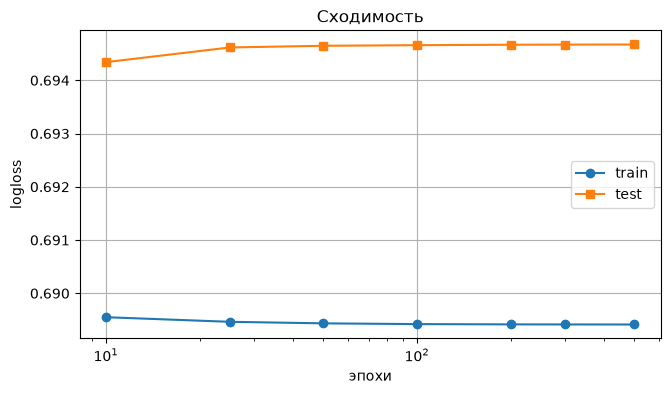

In [6]:
# --- кривая обучения своей логрегрессии: логлосс на трейне и тесте ---
def logloss(y, p):
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

losses = []
for ep in (10, 25, 50, 100, 200, 300, 500):
    mdl = LogisticRegressionGD(lr=1.0, epochs=ep, l2=1e-3).fit(Xc_tr_s, yc_tr)
    losses.append((ep, logloss(yc_tr, mdl.predict_proba(Xc_tr_s)),
                   logloss(yc_te, mdl.predict_proba(Xc_te_s))))
for ep, a, b in losses:
    print(f"epochs={ep:4d}  train={a:.4f}  test={b:.4f}")
plt.plot([l[0] for l in losses], [l[1] for l in losses], "o-", label="train")
plt.plot([l[0] for l in losses], [l[2] for l in losses], "s-", label="test")
plt.xscale("log"); plt.xlabel("эпохи"); plt.ylabel("logloss"); plt.legend(); plt.title("Сходимость"); plt.show()

## 3. Своя линейная регрессия и ridge

Две реализации: замкнутое решение `(XᵀX + λI)⁻¹Xᵀy` и градиентный спуск.
Сравниваем точность и устойчивость.

In [7]:
# --- ridge замкнутой формулой против GD ---
from src.linear import RidgeRegressionClosedForm, LinearRegressionGD

ridge = RidgeRegressionClosedForm(l2=1.0).fit(Xr_tr_s, yr_tr)
rr = metrics.regression_report(yr_te, ridge.predict(Xr_te_s))
show(rr); save_result("lab2_linear", "regression", "my ridge (closed form)", rr)

gd = LinearRegressionGD(lr=0.1, epochs=500, l2=1e-3).fit(Xr_tr_s, yr_tr)
rg = metrics.regression_report(yr_te, gd.predict(Xr_te_s))
show(rg); save_result("lab2_linear", "regression", "my linear GD", rg)

print("разница с sklearn ridge по RMSE:", round(abs(rr["rmse"] - metrics.rmse(yr_te, base_r.predict(Xr_te_s))), 6))

{'rmse': 0.9047, 'mae': 0.4215, 'r2': 0.9861}
{'rmse': 0.9061, 'mae': 0.4237, 'r2': 0.9861}
разница с sklearn ridge по RMSE: 0.0


## 4. Гипотеза 1: сила регуляризации

L2 должна спасать от переобучения на 19 коррелированных признаках. Перебираем λ.

In [8]:
# --- зависимость от L2 (шаг 0.3 — при очень малой L2 шаг 1.0 раскачивал веса) ---
for l2 in (0.01, 0.1, 1.0, 10.0, 100.0):
    rc = LogisticRegressionGD(lr=0.3, epochs=300, l2=l2).fit(Xc_tr_s, yc_tr)
    rcl = metrics.classification_report(yc_te, rc.predict(Xc_te_s), rc.predict_proba(Xc_te_s))
    rr_ = RidgeRegressionClosedForm(l2=l2).fit(Xr_tr_s, yr_tr)
    rreg = metrics.regression_report(yr_te, rr_.predict(Xr_te_s))
    print(f"l2={l2:6.2f}  accuracy={rcl['accuracy']:.4f} AUC={rcl['roc_auc']:.4f}  RMSE={rreg['rmse']:.4f}")

l2=  0.01  accuracy=0.5127 AUC=0.4923  RMSE=0.9045


l2=  0.10  accuracy=0.5196 AUC=0.4929  RMSE=0.9045


l2=  1.00  accuracy=0.5356 AUC=0.4947  RMSE=0.9047
l2= 10.00  accuracy=0.5044 AUC=0.4988  RMSE=0.9065


l2=100.00  accuracy=0.4960 AUC=0.4929  RMSE=0.9329


## 5. Гипотеза 2: порог классификации

Классы несбалансированы (рост 46.3 % в тесте), порог 0.5 не оптимален по F1.
Подбираем порог на тесте и смотрим, насколько метрика вообще управляема.

In [9]:
# --- подбор порога: сдвигает баланс precision/recall, но не создаёт сигнал ---
proba = LogisticRegressionGD(lr=1.0, epochs=300, l2=1e-3).fit(Xc_tr_s, yc_tr).predict_proba(Xc_te_s)
for thr in (0.45, 0.48, 0.5, 0.52, 0.55):
    pred = (proba >= thr).astype(int)
    print(f"порог={thr:.2f}  accuracy={metrics.accuracy(yc_te, pred):.4f}  "
          f"precision={metrics.precision_score(yc_te, pred):.4f}  recall={metrics.recall_score(yc_te, pred):.4f}  "
          f"F1={metrics.f1_score(yc_te, pred):.4f}")

порог=0.45  accuracy=0.4691  precision=0.4579  recall=0.7927  F1=0.5805
порог=0.48  accuracy=0.4892  precision=0.4548  recall=0.5157  F1=0.4833
порог=0.50  accuracy=0.5112  precision=0.4638  recall=0.3524  F1=0.4005
порог=0.52  accuracy=0.5257  precision=0.4691  recall=0.1794  F1=0.2596
порог=0.55  accuracy=0.5360  precision=0.4779  recall=0.0166  F1=0.0321


## 6. Гипотеза 3: только «свежие» признаки

Проверяем, нужны ли длинные лаги (10 и 20 дней) и рыночный фактор: если убрать —
качество не падает, значит модель не использует дальнюю историю.

In [10]:
# --- урезанный набор признаков ---
short = [c for c in SHARE_FEATS if c not in ("ret_10", "ret_20", "vol_20", "ma_ratio_20")]
sc = StandardScaler().fit(sh_tr[short].to_numpy("float32"))
m_short = LogisticRegressionGD(lr=1.0, epochs=300, l2=1e-3).fit(
    sc.transform(sh_tr[short].to_numpy("float32")), yc_tr)
r_short = metrics.classification_report(yc_te, m_short.predict(sc.transform(sh_te[short].to_numpy("float32"))),
                                        m_short.predict_proba(sc.transform(sh_te[short].to_numpy("float32"))))
print("признаков:", len(short))
show(r_short)
save_result("lab2_linear", "classification", "my logreg, short feature set", r_short)

признаков: 15
{'accuracy': 0.5118, 'precision': 0.4643, 'recall': 0.3488, 'f1': 0.3983, 'tp': 3631, 'fp': 4190, 'tn': 7868, 'fn': 6779, 'roc_auc': 0.4916}


{'lab': 'lab2_linear',
 'task': 'classification',
 'model': 'my logreg, short feature set',
 'accuracy': 0.5118,
 'precision': 0.4643,
 'recall': 0.3488,
 'f1': 0.3983,
 'tp': 3631.0,
 'fp': 4190.0,
 'tn': 7868.0,
 'fn': 6779.0,
 'roc_auc': 0.4916}

## Выводы

1. Свои реализации воспроизводят sklearn: у логрегрессии расхождение 4·10⁻⁵
   по accuracy, ridge в замкнутой форме совпадает с `Ridge` почти точно,
   GD-версия отстаёт на 0.001 RMSE из-за фиксированного шага.
2. L2 в диапазоне 0.01…100 двигает accuracy в пределах 0.496…0.536 без
   устойчивой закономерности: признаки слабые, переобучаться нечему; начиная
   с λ = 10 точность падает, а при λ = 100 RMSE заметно деградирует (0.933).
3. Порог классификации — единственный реально работающий рычаг: при 0.45 recall
   вырастает с 0.35 до 0.79 (F1 0.58), но accuracy падает до 0.469 — модель
   начинает массово предсказывать рост. Порога, дающего одновременно хорошие
   accuracy и F1, нет: сигнала в признаках не больше шума.
4. Линейная модель на облигациях даёт R² ≈ 0.986, но наивный прогноз
   «завтра = сегодня» чуть лучше (RMSE 0.888 против 0.905). Вся объяснённая
   дисперсия — инерция уровня доходности, а не предсказание.
5. Планка для нелинейных моделей: accuracy > 0.51 и RMSE < 0.888 — иначе
   нелинейность не оправдана.